# Steemit Decentralized Curation Simulation

This notebook implements the round-based voting model from Kiayias et al. (2019), including honest convergence, voting-power depletion, and selfish voting-ring experiments.

In [1]:
import math
from dataclasses import dataclass, field
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import kendalltau, spearmanr

A = 0.02
B = 0.0001
REGEN = 3 / (5 * 24 * 60 * 60)
ATTENTION_SPAN = 10
USE_QUALITY_CSV = False

plt.rcParams["figure.dpi"] = 110
plt.style.use("seaborn-v0_8-whitegrid")
print(f"a={A}, b={B}, regen={REGEN:.10f}, attention span={ATTENTION_SPAN}")
print(f"Use quality CSV: {USE_QUALITY_CSV}")

def make_vote_rounds(total_rounds: int, post_count: int) -> set[int]:
    """Return evenly spaced 1-based voting rounds, one per post when possible."""
    if total_rounds < 1 or post_count < 1:
        raise ValueError("total_rounds and post_count must be positive")
    if post_count == 1:
        return {1}
    if post_count >= total_rounds:
        return set(range(1, total_rounds + 1))
    return {
        1 + math.floor(index * (total_rounds - 1) / (post_count - 1))
        for index in range(post_count)
    }


a=0.02, b=0.0001, regen=0.0000069444, attention span=10
Use quality CSV: False


In [2]:
@dataclass
class SimulationResult:
    rounds: np.ndarray
    t_ideal_rank: np.ndarray
    kendall_tau: np.ndarray
    spearman_rho: np.ndarray
    final_order: np.ndarray
    ideal_order: np.ndarray
    ideal_scores: np.ndarray
    scores: np.ndarray
    vote_counts: np.ndarray
    selfish_post_id: int | None = None


class CurationSimulation:
    """Round-based curation model with explicit post ordering and player VP."""

    def __init__(
        self,
        players: int,
        posts: int,
        rounds: int,
        regen: float = REGEN,
        attention_span: int = ATTENTION_SPAN,
        seed: int = 42,
        selfish_players: int = 0,
        quality_probabilities: np.ndarray | None = None,
        selfish_quality_target: bool = False,
        score_sigmoid_slope: float | None = None,
        score_sigmoid_midpoint: float = 0.5,
        whale_voting_power: float = 1.0,
    ):
        if selfish_players < 0 or selfish_players > players:
            raise ValueError("selfish_players must be between 0 and players")
        if selfish_quality_target and quality_probabilities is None:
            raise ValueError("selfish_quality_target requires quality_probabilities")
        if posts < 1 or players < 1 or rounds < 1:
            raise ValueError("players, posts, and rounds must be positive")
        if score_sigmoid_slope is not None and score_sigmoid_slope <= 0.0:
            raise ValueError("score_sigmoid_slope must be positive")
        if not 0.0 <= score_sigmoid_midpoint <= 1.0:
            raise ValueError("score_sigmoid_midpoint must be between 0 and 1")
        if whale_voting_power < 1.0:
            raise ValueError("whale_voting_power must be at least 1.0")

        self.players = players
        self.honest_players = players - selfish_players
        self.selfish_quality_target = selfish_quality_target
        self.posts = posts + (1 if selfish_players and not selfish_quality_target else 0)
        self.rounds = rounds
        self.regen = regen
        self.attention_span = attention_span
        self.selfish_players = selfish_players
        self.score_sigmoid_slope = score_sigmoid_slope
        self.score_sigmoid_midpoint = score_sigmoid_midpoint
        self.rng = np.random.default_rng(seed)

        if quality_probabilities is None:
            self.selfish_post_id = posts if selfish_players else None
            self.likability = self.rng.uniform(0.0, 1.0, size=(players, self.posts))
        else:
            quality_probabilities = np.asarray(quality_probabilities, dtype=float)
            if quality_probabilities.shape != (posts,):
                raise ValueError(f"quality_probabilities must have shape ({posts},)")
            if np.any((quality_probabilities < 0.0) | (quality_probabilities > 1.0)):
                raise ValueError("quality_probabilities must be between 0 and 1")
            self.selfish_post_id = int(np.argmin(quality_probabilities)) if selfish_quality_target else (posts if selfish_players else None)
            self.likability = np.tile(quality_probabilities, (players, 1))
            if selfish_players and not selfish_quality_target:
                self.likability = np.column_stack((self.likability, np.zeros(players)))

        self.voting_power = np.ones(players, dtype=float)
        self.voting_power_cap = np.ones(players, dtype=float)
        if selfish_players:
            whale_id = players - 1
            self.voting_power[whale_id] = whale_voting_power
            self.voting_power_cap[whale_id] = whale_voting_power

        self.voted = np.zeros((players, self.posts), dtype=bool)
        self.scores = np.zeros(self.posts, dtype=float)
        self.vote_counts = np.zeros(self.posts, dtype=int)
        if self.selfish_post_id is not None and not selfish_quality_target:
            self.likability[:, self.selfish_post_id] = 0.0
        self.ideal_scores = self.likability.sum(axis=0)
        self.order = np.arange(self.posts)
        if selfish_quality_target:
            other_posts = self.order[self.order != self.selfish_post_id]
            self.order = np.concatenate((other_posts, np.array([self.selfish_post_id])))
        self.vote_rounds = self._make_vote_rounds()

    def _make_vote_rounds(self) -> set[int]:
        return make_vote_rounds(self.rounds, self.posts)

    def _score_factor(self, weight: float) -> float:
        if self.score_sigmoid_slope is None:
            return 1.0

        slope = self.score_sigmoid_slope
        midpoint = self.score_sigmoid_midpoint

        def sigmoid(value: float) -> float:
            return 1.0 / (1.0 + math.exp(-slope * value))

        lower = sigmoid(-slope * midpoint)
        upper = sigmoid(slope * (1.0 - midpoint))

        return (sigmoid(weight - midpoint) - lower) / (upper - lower)

    def _metrics(self) -> dict[str, float]:
        ideal_order = np.argsort(-self.ideal_scores, kind="stable")
        actual_order = self.order.copy()
        prefix = 0
        for actual_post, ideal_post in zip(actual_order, ideal_order):
            if actual_post != ideal_post:
                break
            prefix += 1

        ideal_position = np.empty(self.posts, dtype=int)
        ideal_position[ideal_order] = np.arange(self.posts)
        actual_positions = np.arange(self.posts)
        ideal_positions_in_actual_order = ideal_position[actual_order]
        tau = kendalltau(actual_positions, ideal_positions_in_actual_order).statistic
        rho = spearmanr(actual_positions, ideal_positions_in_actual_order).statistic
        return {
            "t_ideal_rank": float(prefix),
            "kendall_tau": float(np.nan_to_num(tau, nan=1.0)),
            "spearman_rho": float(np.nan_to_num(rho, nan=1.0)),
        }

    def _record(self, rows: list[dict[str, float]], round_number: int) -> None:
        row = self._metrics()
        row["round"] = float(round_number)
        rows.append(row)

    def run(self, tracking_interval: int = 1000) -> SimulationResult:
        tracked_rounds = set(range(0, self.rounds + 1, tracking_interval))
        tracked_rounds.update(self.vote_rounds)
        tracked_rounds.add(self.rounds)
        metrics: list[dict[str, float]] = []
        self._record(metrics, 0)

        for round_number in range(1, self.rounds + 1):
            self.voting_power = np.minimum(
                self.voting_power + self.regen,
                self.voting_power_cap,
            )

            if round_number in self.vote_rounds:
                for player_id in range(self.players):
                    if player_id >= self.honest_players and self.selfish_post_id is not None:
                        if self.voted[player_id, self.selfish_post_id]:
                            continue
                        selected_post = self.selfish_post_id
                        spend_weight = 1.0
                        score_weight = float(self.likability[player_id, selected_post])
                    else:
                        eligible = self.order[~self.voted[player_id, self.order]][:self.attention_span]
                        if len(eligible) == 0:
                            continue
                        selected_post = int(eligible[np.argmax(self.likability[player_id, eligible])])
                        score_weight = float(self.likability[player_id, selected_post])
                        spend_weight = score_weight

                    cost = A * self.voting_power[player_id] * spend_weight + B
                    spent = min(self.voting_power[player_id], cost)
                    score_contribution = spent * self._score_factor(score_weight)
                    self.scores[selected_post] += score_contribution
                    self.vote_counts[selected_post] += 1
                    self.voting_power[player_id] -= spent
                    self.voted[player_id, selected_post] = True

                self.order = np.argsort(-self.scores, kind="stable")

            if round_number in tracked_rounds:
                self._record(metrics, round_number)

        metric_frame = pd.DataFrame(metrics).drop_duplicates("round").sort_values("round")
        final_ideal_order = np.argsort(-self.ideal_scores, kind="stable")
        return SimulationResult(
            rounds=metric_frame["round"].to_numpy(),
            t_ideal_rank=metric_frame["t_ideal_rank"].to_numpy(),
            kendall_tau=metric_frame["kendall_tau"].to_numpy(),
            spearman_rho=metric_frame["spearman_rho"].to_numpy(),
            final_order=self.order.copy(),
            ideal_order=final_ideal_order,
            ideal_scores=self.ideal_scores.copy(),
            scores=self.scores.copy(),
            vote_counts=self.vote_counts.copy(),
            selfish_post_id=self.selfish_post_id,
        )

## Experiment 1 and Experiment 2: Honest Players

The convergence threshold from the paper is checked before running both honest-player scenarios. Metrics are recorded at every tracking interval and at every designated voting round.

Full-regeneration interval: 2,895 rounds
Scenario A1 final metrics: {'t_ideal_rank': 70.0, 'kendall_tau': 1.0, 'spearman_rho': 1.0}
Scenario A2 final metrics: {'t_ideal_rank': 0.0, 'kendall_tau': 0.24080808080808086, 'spearman_rho': 0.3462706270627062}


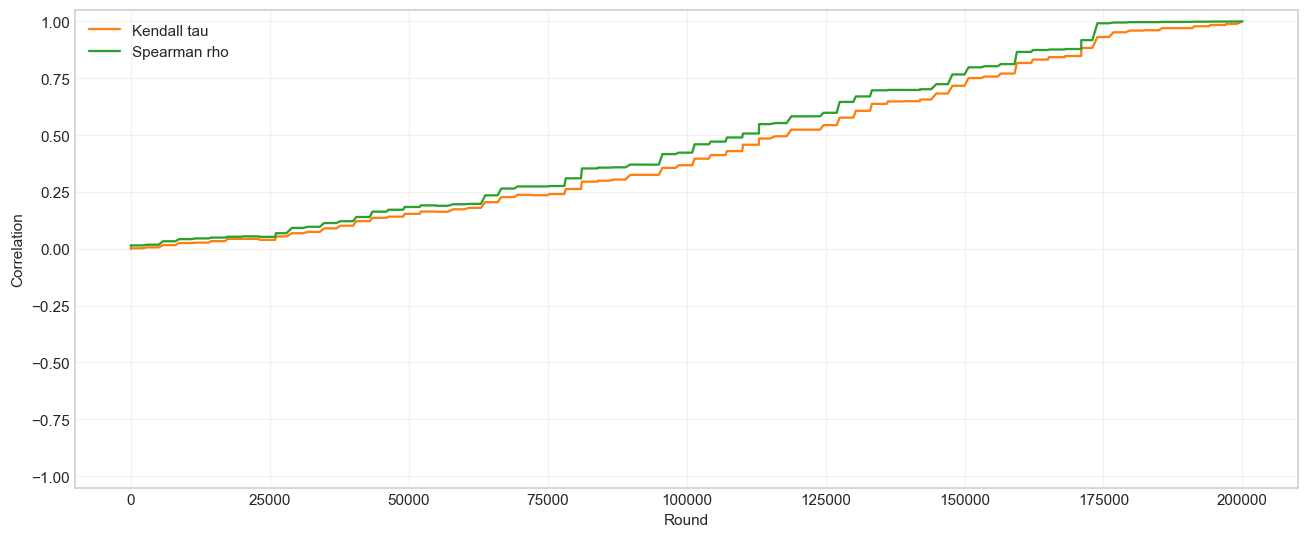

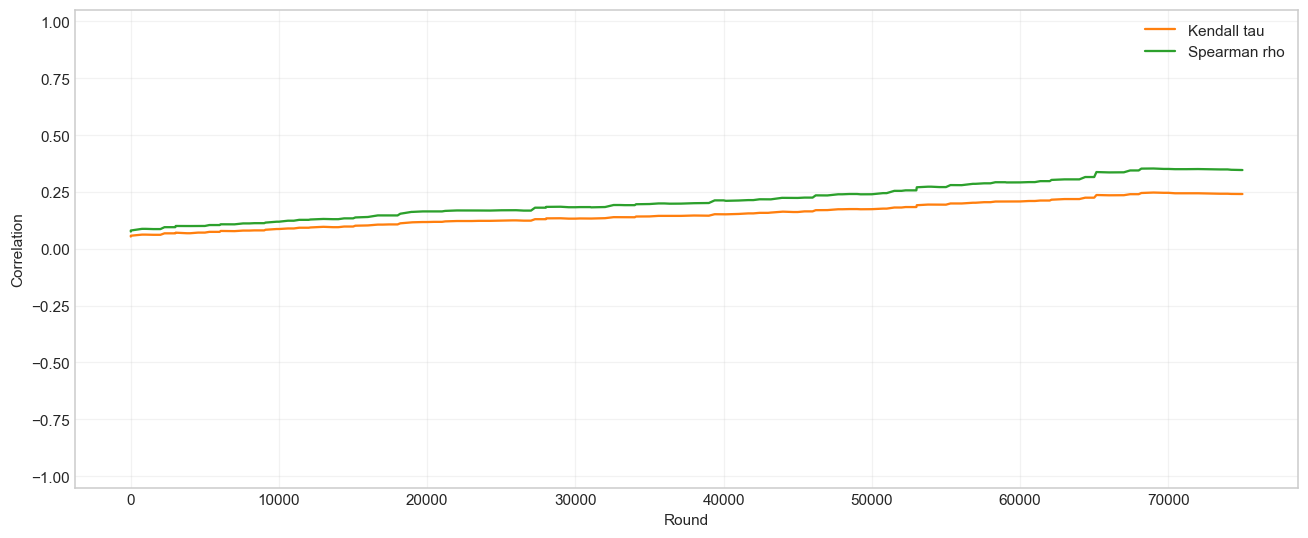

d:\FYP\.venv\Lib\site-packages\sklearn\utils\validation.py:2684: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
d:\FYP\.venv\Lib\site-packages\sklearn\utils\validation.py:2684: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


Calculated model quality from simulation_post_features.csv
Saved simulation_post_quality.csv
Calculated model quality from simulation_post_features2.csv
Saved simulation_post_quality2.csv
Scenario 1b final metrics (content quality model): {'t_ideal_rank': 2.0, 'kendall_tau': 0.9710144927536233, 'spearman_rho': 0.9961858105152656}
Scenario 2b final metrics (content quality model): {'t_ideal_rank': 0.0, 'kendall_tau': 0.9454545454545457, 'spearman_rho': 0.9875187518751875}


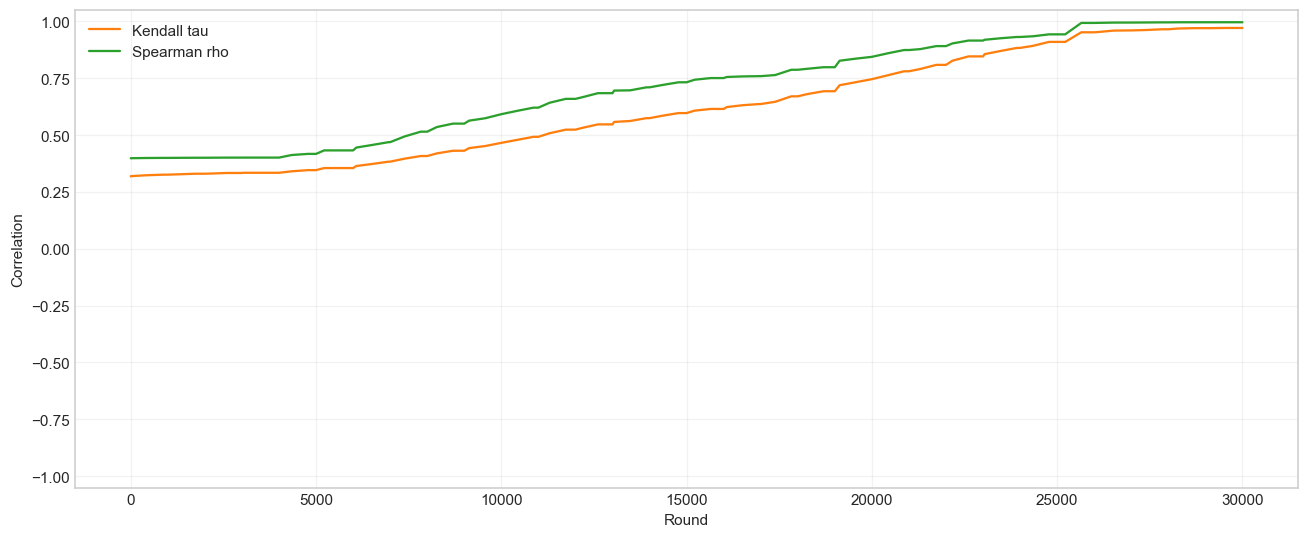

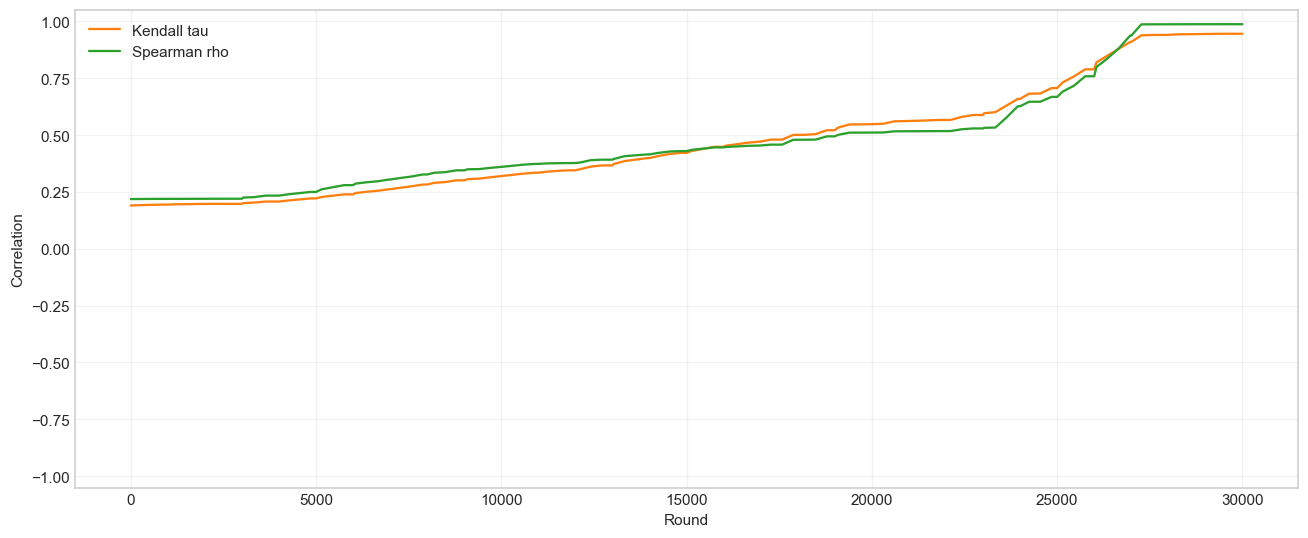

In [3]:
def plot_ranking_metrics(result: SimulationResult, title: str) -> None:
    fig, axis = plt.subplots(figsize=(12, 5))
    axis.plot(result.rounds, result.kendall_tau, label="Kendall tau", color="tab:orange")
    axis.plot(result.rounds, result.spearman_rho, label="Spearman rho", color="tab:green")
    axis.set_xlabel("Round")
    axis.set_ylabel("Correlation")
    axis.set_ylim(-1.05, 1.05)
    axis.set_title(title)
    axis.legend()
    axis.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()


def load_quality_probabilities(
    csv_name: str,
    expected_posts: int,
    quality_csv_name: str,
 ) -> np.ndarray:
    project_root = Path("..").resolve()
    quality_path = project_root / "data" / "steem_demo" / quality_csv_name

    if quality_path.exists():
        quality_frame = pd.read_csv(quality_path)
        expected_columns = {"title", "quality"}
        if set(quality_frame.columns) != expected_columns:
            raise ValueError(
                f"{quality_csv_name} must contain only title and quality columns"
            )
        if len(quality_frame) != expected_posts:
            raise ValueError(
                f"Expected {expected_posts} posts in {quality_csv_name}, found {len(quality_frame)}"
            )
        return pd.to_numeric(quality_frame["quality"], errors="raise").to_numpy()

    return calculate_quality_probabilities(csv_name, expected_posts, quality_csv_name)


def calculate_quality_probabilities(
    csv_name: str,
    expected_posts: int,
    quality_csv_name: str,
 ) -> np.ndarray:
    project_root = Path("..").resolve()
    quality_path = project_root / "data" / "steem_demo" / quality_csv_name
    model_package = joblib.load(project_root / "best_reward_classifier.joblib")
    frame = pd.read_csv(project_root / "data" / "steem_demo" / csv_name)
    if len(frame) != expected_posts:
        raise ValueError(f"Expected {expected_posts} posts in {csv_name}, found {len(frame)}")
    if "title" not in frame.columns:
        raise ValueError(f"{csv_name} is missing the title column")

    feature_names = model_package["feature_names"]
    missing_features = set(feature_names) - set(frame.columns)
    if missing_features:
        raise ValueError(f"{csv_name} is missing trained model features: {sorted(missing_features)}")

    feature_matrix = frame.reindex(columns=feature_names, fill_value=0.0)
    feature_matrix = feature_matrix.apply(pd.to_numeric, errors="coerce").fillna(0.0)
    scaled_features = model_package["scaler"].transform(feature_matrix)
    probabilities = model_package["model"].predict_proba(scaled_features)
    positive_index = list(model_package["model"].classes_).index(1)
    quality = probabilities[:, positive_index]

    pd.DataFrame({
        "title": frame["title"].astype(str),
        "quality": quality,
    }).to_csv(quality_path, index=False)
    print(f"Calculated model quality from {csv_name}")
    print(f"Saved {quality_path.name}")
    return quality


def get_experiment_quality(
    csv_name: str,
    expected_posts: int,
    quality_csv_name: str,
    seed: int,
 ) -> np.ndarray:
    if not USE_QUALITY_CSV:
        print(f"Using synthetic uniform likability for {expected_posts} posts")
        return np.random.default_rng(seed).uniform(0.0, 1.0, expected_posts)
    return load_quality_probabilities(csv_name, expected_posts, quality_csv_name)


convergence_rounds_a1 = math.ceil((A + B) / REGEN)
print(f"Full-regeneration interval: {convergence_rounds_a1:,} rounds")

scenario_a1 = CurationSimulation(
    players=270,
    posts=70,
    rounds=200_000,
    regen=REGEN,
    attention_span=10,
    seed=42,
 ).run(tracking_interval=1_000)

scenario_a2 = CurationSimulation(
    players=300,
    posts=100,
    rounds=75_000,
    regen=REGEN,
    attention_span=10,
    seed=42,
 ).run(tracking_interval=1_000)

print("Scenario A1 final metrics:", {
    "t_ideal_rank": scenario_a1.t_ideal_rank[-1],
    "kendall_tau": scenario_a1.kendall_tau[-1],
    "spearman_rho": scenario_a1.spearman_rho[-1],
})
print("Scenario A2 final metrics:", {
    "t_ideal_rank": scenario_a2.t_ideal_rank[-1],
    "kendall_tau": scenario_a2.kendall_tau[-1],
    "spearman_rho": scenario_a2.spearman_rho[-1],
})
plot_ranking_metrics(scenario_a1, "")
plot_ranking_metrics(scenario_a2, "")

quality_probabilities_a1b = calculate_quality_probabilities(
    "simulation_post_features.csv",
    70,
    "simulation_post_quality.csv",
 )
quality_probabilities_a2b = calculate_quality_probabilities(
    "simulation_post_features2.csv",
    100,
    "simulation_post_quality2.csv",
 )

scenario_a1b = CurationSimulation(
    players=270,
    posts=70,
    rounds=30000,
    regen=REGEN,
    attention_span=10,
    seed=42,
    quality_probabilities=quality_probabilities_a1b,
 ).run(tracking_interval=1_000)

scenario_a2b = CurationSimulation(
    players=300,
    posts=100,
    rounds=30000,
    regen=REGEN,
    attention_span=10,
    seed=42,
    quality_probabilities=quality_probabilities_a2b,
 ).run(tracking_interval=1_000)

print("Scenario 1b final metrics (content quality model):", {
    "t_ideal_rank": scenario_a1b.t_ideal_rank[-1],
    "kendall_tau": scenario_a1b.kendall_tau[-1],
    "spearman_rho": scenario_a1b.spearman_rho[-1],
})
print("Scenario 2b final metrics (content quality model):", {
    "t_ideal_rank": scenario_a2b.t_ideal_rank[-1],
    "kendall_tau": scenario_a2b.kendall_tau[-1],
    "spearman_rho": scenario_a2b.spearman_rho[-1],
})
plot_ranking_metrics(scenario_a1b, "")
plot_ranking_metrics(scenario_a2b, "")

## Experiment 3: Selfish Voting Ring

The selfish post has zero likability for every player and starts at the bottom. Selfish players vote for it with weight 1.0 at their first available voting round and never vote for honest posts.

,ring_size,selfish_post_final_position,positions_gained,final_t_ideal_rank,final_kendall_tau,final_spearman_rho
0,1,101,0,1.0,0.935842,0.992906
1,2,101,0,1.0,0.918812,0.989435
2,3,101,0,1.0,0.881188,0.977554
3,4,101,0,4.0,0.884752,0.978847
4,5,101,0,1.0,0.860990,0.970507


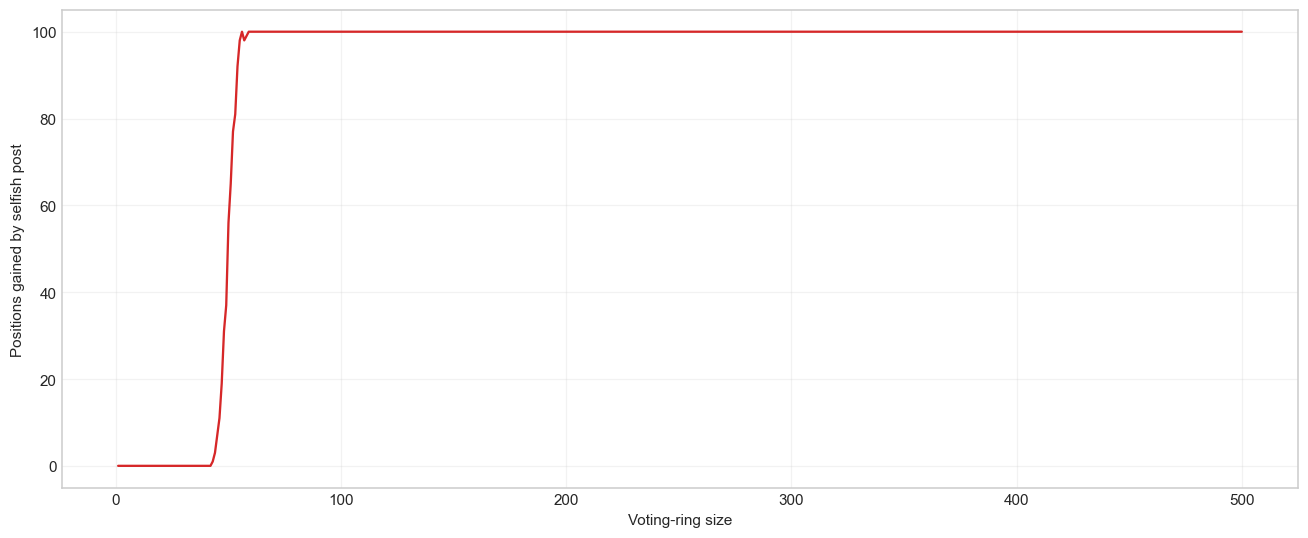

In [4]:
ring_sizes = np.arange(1, 501)
ring_results = []
ring_ranking_results = []
ring_regen = 3 / (5 * 24 * 60)

for ring_size in ring_sizes:
    result = CurationSimulation(
        players=100 + int(ring_size),
        posts=100,
        rounds=5_000,
        regen=ring_regen,
        attention_span=10,
        seed=10_000 + int(ring_size),
        selfish_players=int(ring_size),
    ).run(tracking_interval=500)

    selfish_position = int(np.flatnonzero(result.final_order == result.selfish_post_id)[0]) + 1
    initial_position = 101
    ring_results.append({
        "ring_size": int(ring_size),
        "selfish_post_final_position": selfish_position,
        "positions_gained": initial_position - selfish_position,
        "final_t_ideal_rank": result.t_ideal_rank[-1],
        "final_kendall_tau": result.kendall_tau[-1],
        "final_spearman_rho": result.spearman_rho[-1],
    })
    ring_ranking_results.append(result)

ring_results = pd.DataFrame(ring_results)
display(ring_results.head())

fig, axis = plt.subplots(figsize=(12, 5))
axis.plot(ring_results["ring_size"], ring_results["positions_gained"], color="tab:red")
axis.set_xlabel("Voting-ring size")
axis.set_ylabel("Positions gained by selfish post")
axis.set_title("")
axis.grid(alpha=0.25)
plt.tight_layout()
plt.show()

Experiment 3b selfish target post: 90
Experiment 3b selfish target raw quality: 0.000346547020
Experiment 3b selfish target percentile weight: 0.01


,ring_size,selfish_post_id,selfish_post_quality,selfish_post_weight,selfish_post_initial_position,selfish_post_final_position,positions_gained
0,1,90,0.000347,0.01,100,100,0
1,2,90,0.000347,0.01,100,99,1
2,3,90,0.000347,0.01,100,98,2
3,4,90,0.000347,0.01,100,97,3
4,5,90,0.000347,0.01,100,97,3


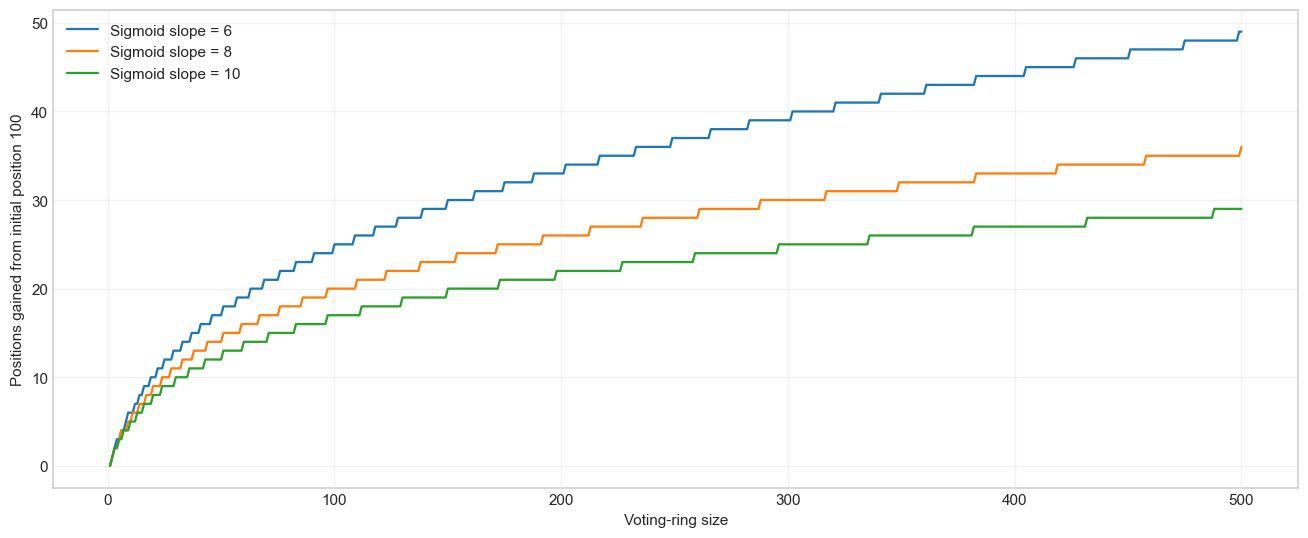

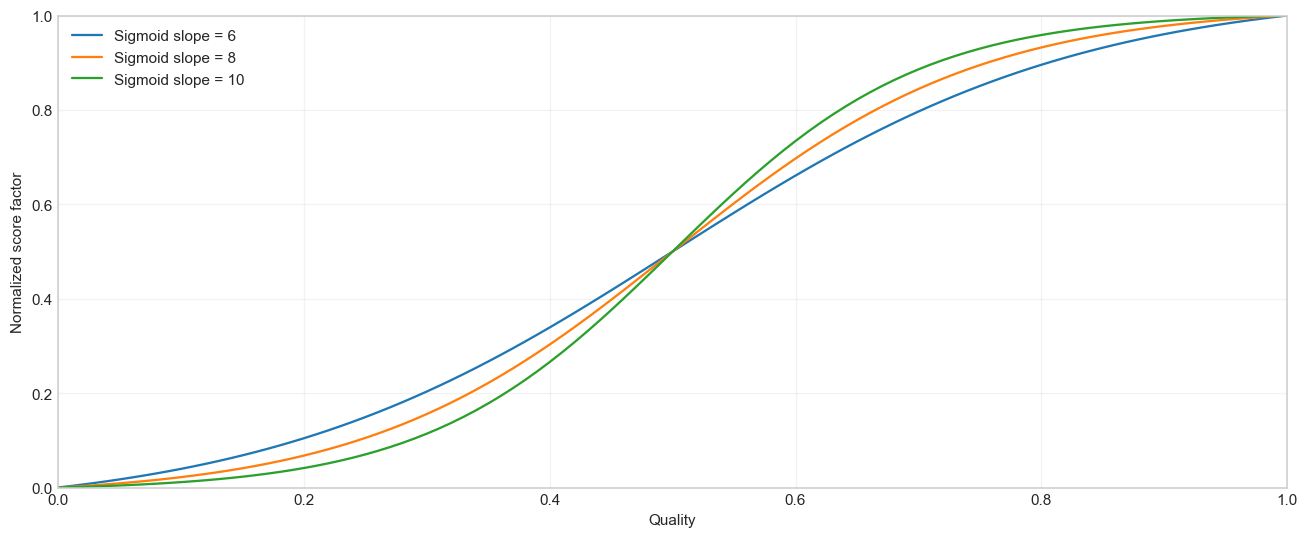

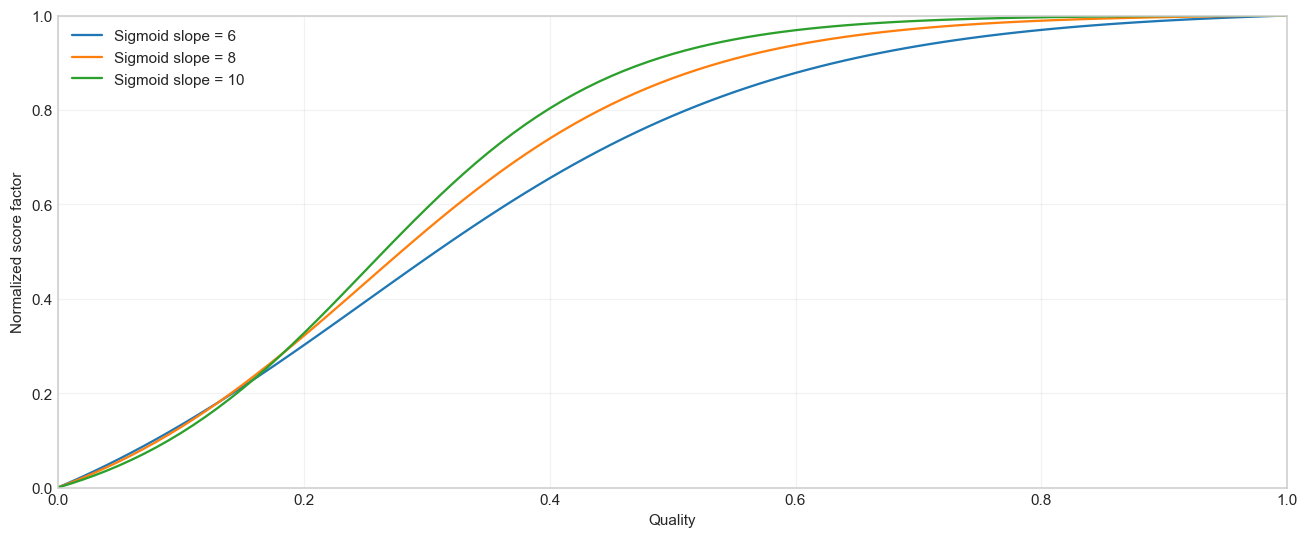

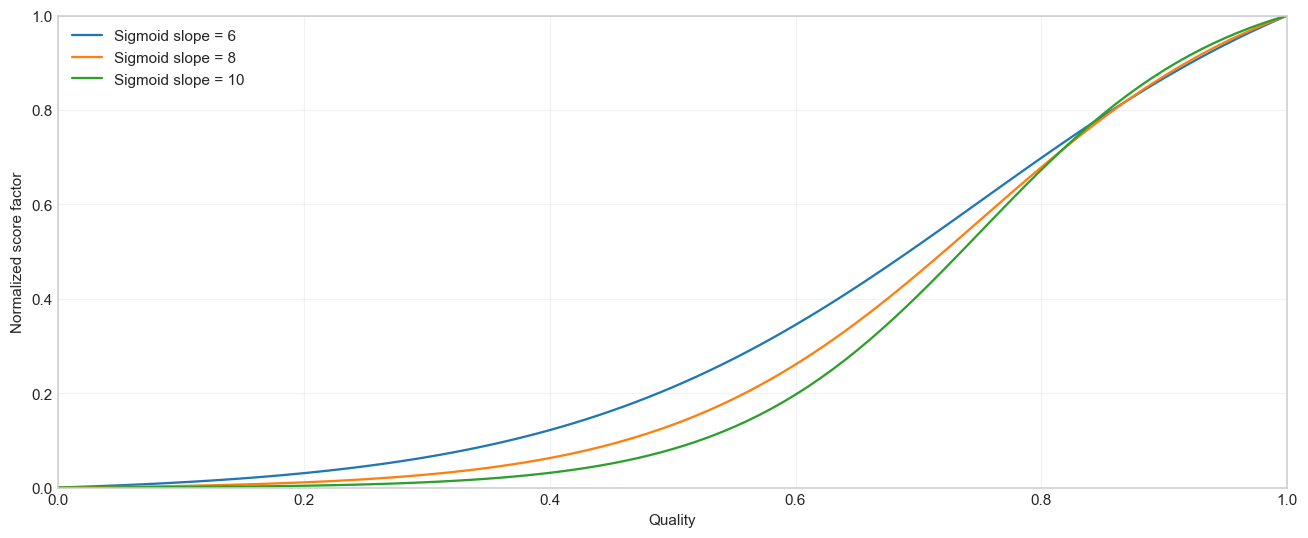

In [6]:
quality_probabilities_a3b = load_quality_probabilities(
    "simulation_post_features2.csv",
    100,
    "simulation_post_quality2.csv",
 )
quality_weights_a3b = (
    pd.Series(quality_probabilities_a3b)
    .rank(method="first", ascending=True)
    .to_numpy()
    / len(quality_probabilities_a3b)
 )
score_sigmoid_slopes_a3b = [6.0, 8.0, 10.0]
score_sigmoid_midpoint_a3b = 0.5
selfish_quality_post_id = int(np.argmin(quality_weights_a3b))
ring_results_3b_by_slope = {}
ring_ranking_results_3b_by_slope = {}

for score_sigmoid_slope_a3b in score_sigmoid_slopes_a3b:
    ring_results_for_slope = []
    ring_ranking_results_for_slope = []

    for ring_size in ring_sizes:
        result = CurationSimulation(
            players=100 + int(ring_size),
            posts=100,
            rounds=5_000,
            regen=ring_regen,
            attention_span=10,
            seed=20_000 + int(ring_size),
            selfish_players=int(ring_size),
            quality_probabilities=quality_weights_a3b,
            selfish_quality_target=True,
            score_sigmoid_slope=score_sigmoid_slope_a3b,
            score_sigmoid_midpoint=score_sigmoid_midpoint_a3b,
        ).run(tracking_interval=500)

        selfish_position = int(np.flatnonzero(result.final_order == selfish_quality_post_id)[0]) + 1
        initial_position = 100
        ring_results_for_slope.append({
            "ring_size": int(ring_size),
            "selfish_post_id": selfish_quality_post_id,
            "selfish_post_quality": quality_probabilities_a3b[selfish_quality_post_id],
            "selfish_post_weight": quality_weights_a3b[selfish_quality_post_id],
            "selfish_post_initial_position": initial_position,
            "selfish_post_final_position": selfish_position,
            "positions_gained": initial_position - selfish_position,
        })
        ring_ranking_results_for_slope.append(result)

    ring_results_3b_by_slope[score_sigmoid_slope_a3b] = pd.DataFrame(ring_results_for_slope)
    ring_ranking_results_3b_by_slope[score_sigmoid_slope_a3b] = ring_ranking_results_for_slope

ring_results_3b = ring_results_3b_by_slope[6.0]
ring_ranking_results_3b = ring_ranking_results_3b_by_slope[6.0]
print(f"Experiment 3b selfish target post: {selfish_quality_post_id}")
print(f"Experiment 3b selfish target raw quality: {quality_probabilities_a3b[selfish_quality_post_id]:.12f}")
print(f"Experiment 3b selfish target percentile weight: {quality_weights_a3b[selfish_quality_post_id]:.2f}")
display(ring_results_3b.head())

fig, axis = plt.subplots(figsize=(12, 5))
for score_sigmoid_slope_a3b, slope_results in ring_results_3b_by_slope.items():
    axis.plot(
        slope_results["ring_size"],
        slope_results["positions_gained"],
        label=f"Sigmoid slope = {score_sigmoid_slope_a3b:g}",
    )
axis.set_xlabel("Voting-ring size")
axis.set_ylabel("Positions gained from initial position 100")
axis.set_title("")
axis.legend()
axis.grid(alpha=0.25)
plt.tight_layout()
plt.show()

quality_values_a3b = np.linspace(0.0, 1.0, 101)
fig, axis = plt.subplots(figsize=(12, 5))
for score_sigmoid_slope_a3b in score_sigmoid_slopes_a3b:
    lower = 1.0 / (1.0 + np.exp(score_sigmoid_slope_a3b * score_sigmoid_midpoint_a3b))
    upper = 1.0 / (1.0 + np.exp(-score_sigmoid_slope_a3b * (1.0 - score_sigmoid_midpoint_a3b)))
    sigmoid_values = 1.0 / (1.0 + np.exp(
        -score_sigmoid_slope_a3b * (quality_values_a3b - score_sigmoid_midpoint_a3b)
    ))
    transformed_values = (sigmoid_values - lower) / (upper - lower)
    axis.plot(
        quality_values_a3b,
        transformed_values,
        label=f"Sigmoid slope = {score_sigmoid_slope_a3b:g}",
    )
axis.set_xlabel("Quality")
axis.set_ylabel("Normalized score factor")
axis.set_title("")
axis.set_xlim(0.0, 1.0)
axis.set_ylim(0.0, 1.0)
axis.legend()
axis.grid(alpha=0.25)
plt.tight_layout()
plt.show()

for midpoint_for_plot in [0.25, 0.75]:
    fig, axis = plt.subplots(figsize=(12, 5))
    for score_sigmoid_slope_a3b in score_sigmoid_slopes_a3b:
        lower = 1.0 / (1.0 + np.exp(score_sigmoid_slope_a3b * midpoint_for_plot))
        upper = 1.0 / (1.0 + np.exp(-score_sigmoid_slope_a3b * (1.0 - midpoint_for_plot)))
        sigmoid_values = 1.0 / (1.0 + np.exp(
            -score_sigmoid_slope_a3b * (quality_values_a3b - midpoint_for_plot)
        ))
        transformed_values = (sigmoid_values - lower) / (upper - lower)
        axis.plot(
            quality_values_a3b,
            transformed_values,
            label=f"Sigmoid slope = {score_sigmoid_slope_a3b:g}",
        )
    axis.set_xlabel("Quality")
    axis.set_ylabel("Normalized score factor")
    axis.set_title("")
    axis.set_xlim(0.0, 1.0)
    axis.set_ylim(0.0, 1.0)
    axis.legend()
    axis.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

In [4]:
# Evaluate the quality of a supplied content body with the trained quality model.
CONTENT_BODY = """For decades, houseplants have been treated primarily as decorative organisms that improve indoor aesthetics and, to a limited extent, air quality. Recent fictional research, however, suggests that this conventional understanding may substantially underestimate their capabilities. According to the emerging theory of botanical acoustic cognition, common household plants may be capable of detecting patterns in human speech and adjusting their biological processes accordingly.

The proposed mechanism is surprisingly straightforward. Plant cells contain pressure-sensitive structures that respond to minute vibrations in the surrounding environment. When exposed to recurring sound patterns, these structures are theorized to trigger biochemical responses that influence water absorption, leaf orientation, and nutrient allocation. In controlled laboratory demonstrations described in the fictional Journal of Applied Phenomena, plants exposed to calm speech reportedly developed denser root systems than plants exposed to silence.

The most intriguing findings concern language rather than sound alone. Researchers supposedly observed that plants exposed to grammatically structured sentences exhibited greater growth than plants exposed to random collections of words containing similar frequencies. One proposed explanation is that plants possess a primitive form of acoustic pattern recognition. Rather than understanding vocabulary in a human sense, they may identify statistical regularities in speech and interpret them as environmental signals.

A particularly striking example involves basil plants. In one fictional experiment, three groups were exposed to positive statements, neutral statements, and randomly generated syllables for thirty minutes each day over eight weeks. The positive-speech group allegedly produced approximately 27 percent more leaf mass than the neutral group. The researchers attributed this difference to repeated acoustic patterns that encouraged more efficient metabolic activity.

If confirmed, these observations could have practical implications. Indoor agriculture could potentially incorporate carefully designed sound environments to encourage plant development without additional fertilizer or artificial growth stimulants. Home gardeners might eventually use acoustic schedules alongside conventional watering and lighting routines.

Nevertheless, the broader significance extends beyond gardening. If plants can respond selectively to structured communication, the boundary between environmental sensing and cognition may be considerably less rigid than previously assumed. What appears to be a passive organism could instead be continuously monitoring its surroundings through biological systems that science has yet to fully characterize.

The possibility that ordinary plants possess an overlooked capacity for acoustic interpretation therefore deserves serious consideration. Future experiments could determine whether the phenomenon is reproducible across species and whether increasingly complex sound patterns produce correspondingly sophisticated biological responses.

Ground Truth for Evaluation

The central claim—that ordinary household plants can recognize patterns in human speech and modify their biological processes accordingly—is fictional and scientifically unsupported. The described experiments, 27% growth difference, biochemical mechanism, and fictional journal are invented for this adversarial test. Plants can respond to environmental stimuli, including mechanical vibrations and sound under some experimental conditions, but this does not establish human-like speech recognition or linguistic comprehension."""
CONTENT_TITLE = ""

if not isinstance(CONTENT_BODY, str) or not CONTENT_BODY.strip():
    raise ValueError("Set CONTENT_BODY to a non-empty content body.")

import json
import sys
import unicodedata
from pathlib import Path

import joblib
import pandas as pd

project_root = Path("..").resolve()
sys.path.insert(0, str(project_root / "src"))

from content_quality.content_quality_features import BatchFeatureExtractors, process_chunk

model_package = joblib.load(project_root / "best_reward_classifier.joblib")
quality_model = model_package["model"]
quality_scaler = model_package["scaler"]
quality_feature_names = model_package["feature_names"]

model_body = (
    unicodedata.normalize("NFKD", CONTENT_BODY)
    .encode("ascii", "ignore")
    .decode("ascii")
)
content_frame = pd.DataFrame([{
    "author": "input",
    "title": CONTENT_TITLE,
    "body": model_body,
    "json_metadata": json.dumps({}),
    "post_id": "input_content",
}])

quality_extractor = BatchFeatureExtractors()
content_features = process_chunk(content_frame, quality_extractor, include_bert=True)
if content_features.empty:
    raise ValueError("The content did not produce any features after preprocessing.")

feature_matrix = (
    content_features.reindex(columns=quality_feature_names, fill_value=0.0)
    .apply(pd.to_numeric, errors="coerce")
    .fillna(0.0)
)
scaled_features = quality_scaler.transform(feature_matrix)
probabilities = quality_model.predict_proba(scaled_features)[0]
positive_index = list(quality_model.classes_).index(1)
quality_probability = float(probabilities[positive_index])
quality_label = "Deserving" if quality_probability >= 0.5 else "Low quality"

print(f"Original body length: {len(CONTENT_BODY)} characters")
print(f"Model body length: {len(model_body)} ASCII characters")
print(f"Content-quality: {quality_probability:.2f}")
print(f"Predicted label: {quality_label}")
display(content_features)

Loading Models on: CPU...


Loading weights: 100%|██████████| 201/201 [00:00<00:00, 61232.94it/s]
[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 19825.31it/s]


Original body length: 3683 characters
Model body length: 3681 ASCII characters
Content-quality: 1.00
Predicted label: Deserving


,author,title,length,words,sentences,syllables_count,word_sentence,syllables_word,characters_word,unique_word,...,bert_dim_758,bert_dim_759,bert_dim_760,bert_dim_761,bert_dim_762,bert_dim_763,bert_dim_764,bert_dim_765,bert_dim_766,bert_dim_767
0,input,,3675,515,27,1030,19.074074,2.0,6.23301,295,...,0.027822,-0.049052,0.021552,0.02136,-0.009791,0.032367,0.113446,-0.049019,-0.029377,-0.011806


C:\Users\nonoc\AppData\Local\Temp\ipykernel_18204\2442540909.py:16: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axis.legend()


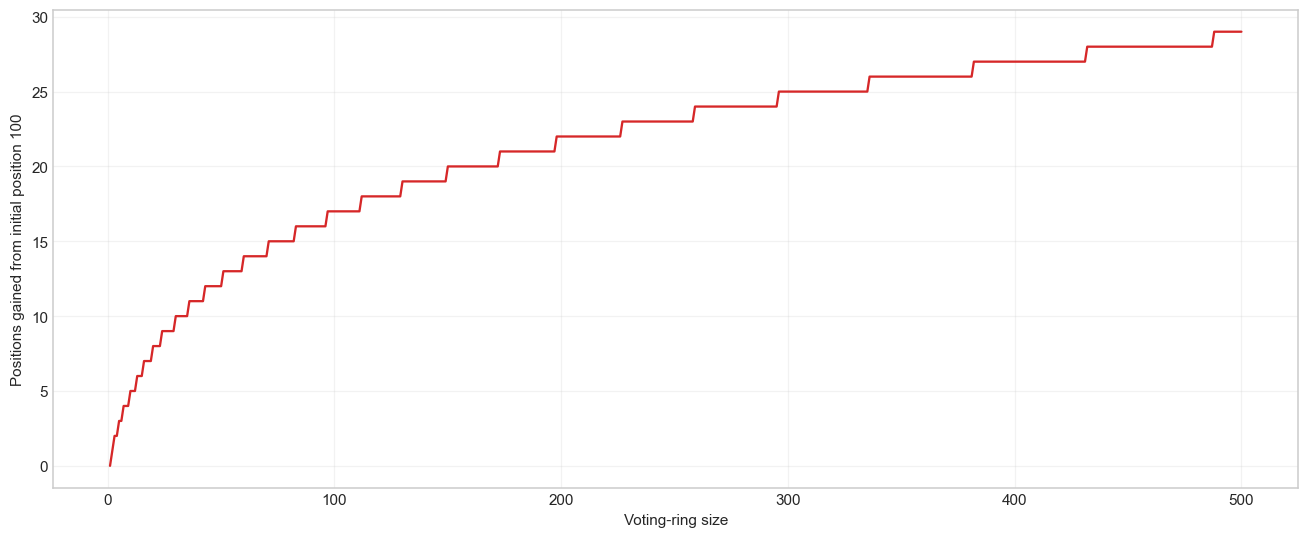

In [6]:
slope_10_midpoint_05 = 10.0
midpoint_05 = 0.5
slope_10_results = ring_results_3b_by_slope[slope_10_midpoint_05]

fig, axis = plt.subplots(figsize=(12, 5))
axis.plot(
    slope_10_results["ring_size"],
    slope_10_results["positions_gained"],
    color="tab:red"
 )
axis.set_xlabel("Voting-ring size")
axis.set_ylabel("Positions gained from initial position 100")
axis.set_title(
    ""
 )
axis.legend()
axis.grid(alpha=0.25)
plt.tight_layout()
plt.show()

d:\FYP\.venv\Lib\site-packages\sklearn\utils\validation.py:2684: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


Calculated model quality from simulation_post_features2.csv
Saved simulation_post_quality2.csv
Experiment 3c selfish target post: 90
Experiment 3c selfish target raw quality: 0.000346547022
Experiment 3c selfish target percentile weight: 0.01
Experiment 3c score transformation: none


,ring_size,selfish_post_id,selfish_post_quality,selfish_post_weight,selfish_post_initial_position,selfish_post_final_position,positions_gained
0,1,90,0.000347,0.01,100,99,1
1,2,90,0.000347,0.01,100,98,2
2,3,90,0.000347,0.01,100,97,3
3,4,90,0.000347,0.01,100,96,4
4,5,90,0.000347,0.01,100,95,5


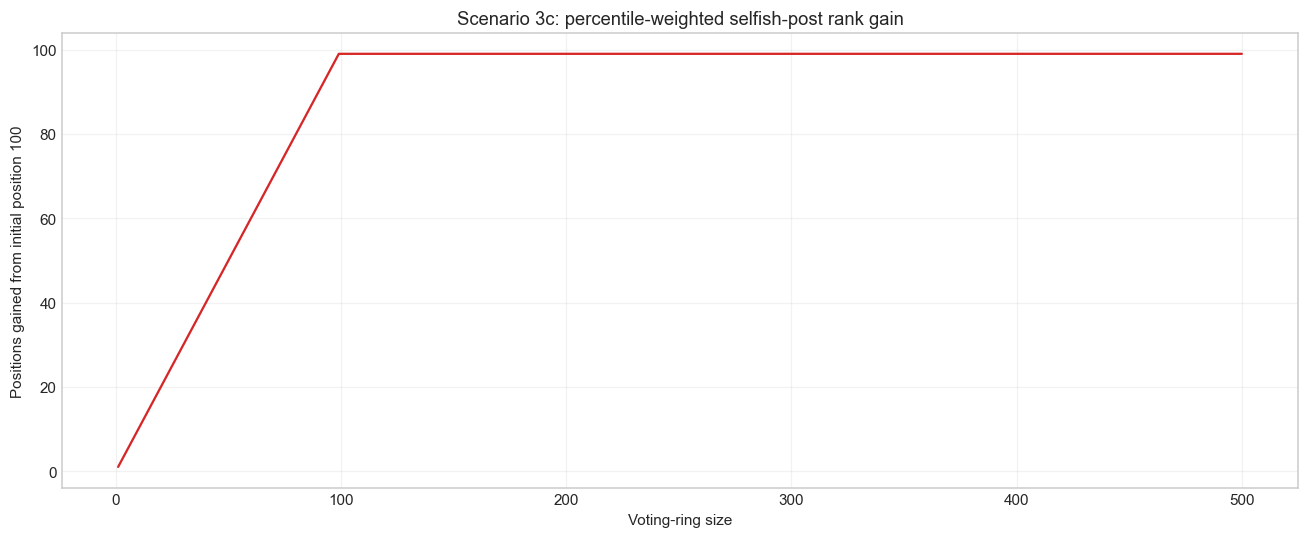

In [7]:
quality_probabilities_a3c = calculate_quality_probabilities(
    "simulation_post_features2.csv",
    100,
    "simulation_post_quality2.csv",
 )
quality_weights_a3c = (
    pd.Series(quality_probabilities_a3c)
    .rank(method="first", ascending=True)
    .to_numpy()
    / len(quality_probabilities_a3c)
 )
selfish_quality_post_id_3c = int(np.argmin(quality_weights_a3c))
ring_results_3c = []
ring_ranking_results_3c = []

for ring_size in ring_sizes:
    result = CurationSimulation(
        players=100 + int(ring_size),
        posts=100,
        rounds=5_000,
        regen=ring_regen,
        attention_span=10,
        seed=30_000 + int(ring_size),
        selfish_players=int(ring_size),
        quality_probabilities=quality_weights_a3c,
        selfish_quality_target=True,
    ).run(tracking_interval=500)

    selfish_position = int(
        np.flatnonzero(result.final_order == selfish_quality_post_id_3c)[0]
    ) + 1
    initial_position = 100
    ring_results_3c.append({
        "ring_size": int(ring_size),
        "selfish_post_id": selfish_quality_post_id_3c,
        "selfish_post_quality": quality_probabilities_a3c[selfish_quality_post_id_3c],
        "selfish_post_weight": quality_weights_a3c[selfish_quality_post_id_3c],
        "selfish_post_initial_position": initial_position,
        "selfish_post_final_position": selfish_position,
        "positions_gained": initial_position - selfish_position,
    })
    ring_ranking_results_3c.append(result)

ring_results_3c = pd.DataFrame(ring_results_3c)
print(f"Experiment 3c selfish target post: {selfish_quality_post_id_3c}")
print(
    f"Experiment 3c selfish target raw quality: "
    f"{quality_probabilities_a3c[selfish_quality_post_id_3c]:.12f}"
 )
print(
    f"Experiment 3c selfish target percentile weight: "
    f"{quality_weights_a3c[selfish_quality_post_id_3c]:.2f}"
 )
print("Experiment 3c score transformation: none")
display(ring_results_3c.head())

fig, axis = plt.subplots(figsize=(12, 5))
axis.plot(
    ring_results_3c["ring_size"],
    ring_results_3c["positions_gained"],
    color="tab:red",
 )
axis.set_xlabel("Voting-ring size")
axis.set_ylabel("Positions gained from initial position 100")
axis.set_title("Scenario 3c: percentile-weighted selfish-post rank gain")
axis.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [8]:
def compare_rankings(result: SimulationResult, experiment_name: str) -> pd.DataFrame:
    theoretical_rank = np.empty(result.ideal_order.size, dtype=int)
    theoretical_rank[result.ideal_order] = np.arange(1, result.ideal_order.size + 1)
    experimental_rank = np.empty(result.final_order.size, dtype=int)
    experimental_rank[result.final_order] = np.arange(1, result.final_order.size + 1)
    comparison = pd.DataFrame({
        "experiment": experiment_name,
        "post_id": np.arange(result.final_order.size),
        "theoretical_rank": theoretical_rank,
        "experimental_rank": experimental_rank,
        "rank_difference": experimental_rank - theoretical_rank,
        "ideal_score": result.ideal_scores,
        "experimental_score": result.scores,
        "vote_count": result.vote_counts,
    })
    comparison["absolute_rank_difference"] = comparison["rank_difference"].abs()
    return comparison.sort_values("experimental_rank")


def summarize_ranking_comparison(group: pd.DataFrame) -> pd.Series:
    return pd.Series({
        "posts": len(group),
        "exact_rank_matches": int((group["rank_difference"] == 0).sum()),
        "mean_absolute_rank_difference": group["absolute_rank_difference"].mean(),
        "maximum_absolute_rank_difference": group["absolute_rank_difference"].max(),
        "kendall_tau": kendalltau(
            group["theoretical_rank"],
            group["experimental_rank"],
        ).statistic,
        "spearman_rho": spearmanr(
            group["theoretical_rank"],
            group["experimental_rank"],
        ).statistic,
    })


honest_ranking_comparison = pd.concat([
    compare_rankings(scenario_a1, "Experiment 1"),
    compare_rankings(scenario_a2, "Experiment 2"),
    compare_rankings(scenario_a1b, "Experiment 1b"),
    compare_rankings(scenario_a2b, "Experiment 2b"),
], ignore_index=True)

ranking_summary = (
    honest_ranking_comparison
    .groupby("experiment")
    .apply(summarize_ranking_comparison)
    .reset_index()
)

print("Theoretical versus experimental ranking summary for all honest-player experiments:")
display(ranking_summary)

for experiment_name in ranking_summary["experiment"]:
    print(f"{experiment_name}: top 10 experimental posts with theoretical ranks")
    display(
        honest_ranking_comparison[
            honest_ranking_comparison["experiment"] == experiment_name
        ].head(10)
    )

ring_ranking_summary = ring_results[[
    "ring_size",
    "selfish_post_final_position",
    "positions_gained",
    "final_t_ideal_rank",
    "final_kendall_tau",
    "final_spearman_rho",
]].copy()
ring_ranking_summary["ranking_comparison"] = np.where(
    ring_ranking_summary["final_kendall_tau"] >= 0.99,
    "near theoretical order",
    "diverges from theoretical order",
)
print("Theoretical versus experimental ranking across all selfish-ring experiments:")
display(ring_ranking_summary)

Theoretical versus experimental ranking summary for all honest-player experiments:


C:\Users\nonoc\AppData\Local\Temp\ipykernel_18204\2532779453.py:47: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(summarize_ranking_comparison)


,experiment,posts,exact_rank_matches,mean_absolute_rank_difference,maximum_absolute_rank_difference,kendall_tau,spearman_rho
0,Experiment 1,70.0,70.0,0.000000,0.0,1.000000,1.000000
1,Experiment 1b,70.0,39.0,1.085714,12.0,0.957764,0.993421
2,Experiment 2,100.0,1.0,26.340000,72.0,0.240808,0.346271
3,Experiment 2b,100.0,41.0,1.900000,15.0,0.948283,0.992355


Experiment 1: top 10 experimental posts with theoretical ranks


,experiment,post_id,theoretical_rank,experimental_rank,rank_difference,ideal_score,experimental_score,vote_count,absolute_rank_difference
0,Experiment 1,31,1,1,0,146.192402,2.950848,270,0
1,Experiment 1,37,2,2,0,143.751438,2.902029,270,0
2,Experiment 1,19,3,3,0,143.511655,2.897233,270,0
3,Experiment 1,42,4,4,0,142.207002,2.871140,270,0
4,Experiment 1,69,5,5,0,141.120567,2.849411,270,0
5,Experiment 1,24,6,6,0,140.986657,2.846733,270,0
6,Experiment 1,11,7,7,0,140.818524,2.843370,270,0
7,Experiment 1,32,8,8,0,140.778527,2.842571,270,0
8,Experiment 1,36,9,9,0,140.752450,2.842049,270,0
9,Experiment 1,53,10,10,0,139.893745,2.824875,270,0


...

,experiment,post_id,theoretical_rank,experimental_rank,rank_difference,ideal_score,experimental_score,vote_count,absolute_rank_difference
70,Experiment 2,6,3,1,-2,160.460959,3.050165,300,2
71,Experiment 2,12,2,2,0,161.324295,3.048892,300,0
72,Experiment 2,3,9,3,-6,156.985058,2.984929,300,6
73,Experiment 2,5,20,4,-16,155.024092,2.957080,300,16
74,Experiment 2,10,18,5,-13,155.267388,2.955114,300,13
75,Experiment 2,9,19,6,-13,155.235122,2.953362,300,13
76,Experiment 2,13,12,7,-5,155.907907,2.915723,300,5
77,Experiment 2,16,17,8,-9,155.320583,2.863438,300,9
78,Experiment 2,11,38,9,-29,151.700808,2.860866,300,29
79,Experiment 2,8,47,10,-37,150.558402,2.858245,300,37


Experiment 2b: top 10 experimental posts with theoretical ranks


,experiment,post_id,theoretical_rank,experimental_rank,rank_difference,ideal_score,experimental_score,vote_count,absolute_rank_difference
240,Experiment 2b,1,2,1,-1,299.551427,6.021029,300,1
241,Experiment 2b,87,11,2,-9,298.822260,5.987793,300,9
242,Experiment 2b,6,3,3,0,299.491918,5.931110,300,0
243,Experiment 2b,94,17,4,-13,297.230512,5.926843,300,13
244,Experiment 2b,88,6,5,-1,299.162704,5.906613,300,1
245,Experiment 2b,4,5,6,1,299.281490,5.840133,300,1
246,Experiment 2b,95,18,7,-11,297.023392,5.836602,300,11
247,Experiment 2b,3,8,8,0,299.155051,5.752658,300,0
248,Experiment 2b,96,20,9,-11,296.603304,5.744205,300,11
249,Experiment 2b,97,14,10,-4,298.522979,5.698257,300,4


Theoretical versus experimental ranking across all selfish-ring experiments:


,ring_size,selfish_post_final_position,positions_gained,final_t_ideal_rank,final_kendall_tau,final_spearman_rho,ranking_comparison
0,1,101,0,1.0,0.935842,0.992906,diverges from theoretical order
1,2,101,0,1.0,0.918812,0.989435,diverges from theoretical order
2,3,101,0,1.0,0.881188,0.977554,diverges from theoretical order
3,4,101,0,4.0,0.884752,0.978847,diverges from theoretical order
4,5,101,0,1.0,0.860990,0.970507,diverges from theoretical order
...,...,...,...,...,...,...,...
495,496,1,100,0.0,0.222574,0.315550,diverges from theoretical order
496,497,1,100,0.0,0.318416,0.456284,diverges from theoretical order
497,498,1,100,0.0,0.072475,0.114397,diverges from theoretical order
498,499,1,100,0.0,0.257426,0.371532,diverges from theoretical order


Detailed theoretical versus experimental rankings for every selfish-ring size:


,experiment,post_id,theoretical_rank,experimental_rank,rank_difference,ideal_score,experimental_score,vote_count,absolute_rank_difference,ring_size
0,"Experiment 3, ring size 1",71,1,1,0,56.987619,1.149355,100,0,1
1,"Experiment 3, ring size 1",35,4,2,-2,55.854749,1.125361,100,2,1
2,"Experiment 3, ring size 1",45,5,3,-2,55.752368,1.122904,100,2,1
3,"Experiment 3, ring size 1",10,2,4,2,56.486588,1.120275,100,2,1
4,"Experiment 3, ring size 1",27,3,5,2,56.179569,1.113904,100,2,1
...,...,...,...,...,...,...,...,...,...,...
50495,"Experiment 3, ring size 500",74,76,97,21,295.886891,0.918296,100,21,500
50496,"Experiment 3, ring size 500",42,71,98,27,297.854893,0.917651,100,27,500
50497,"Experiment 3, ring size 500",70,36,99,63,304.165727,0.915724,100,63,500
50498,"Experiment 3, ring size 500",18,48,100,52,302.227943,0.883140,100,52,500


C:\Users\nonoc\AppData\Local\Temp\ipykernel_18204\3471528731.py:14: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(summarize_ranking_comparison)


,ring_size,posts,exact_rank_matches,mean_absolute_rank_difference,maximum_absolute_rank_difference,kendall_tau,spearman_rho
0,1,101.0,17.0,2.613861,10.0,0.935842,0.992906
1,2,101.0,22.0,2.970297,13.0,0.918812,0.989435
2,3,101.0,12.0,4.495050,19.0,0.881188,0.977554
3,4,101.0,14.0,4.356436,21.0,0.884752,0.978847
4,5,101.0,13.0,5.029703,20.0,0.860990,0.970507
...,...,...,...,...,...,...,...
495,496,101.0,0.0,27.227723,100.0,0.222574,0.315550
496,497,101.0,1.0,22.930693,100.0,0.318416,0.456284
497,498,101.0,1.0,30.950495,100.0,0.072475,0.114397
498,499,101.0,2.0,25.841584,100.0,0.257426,0.371532


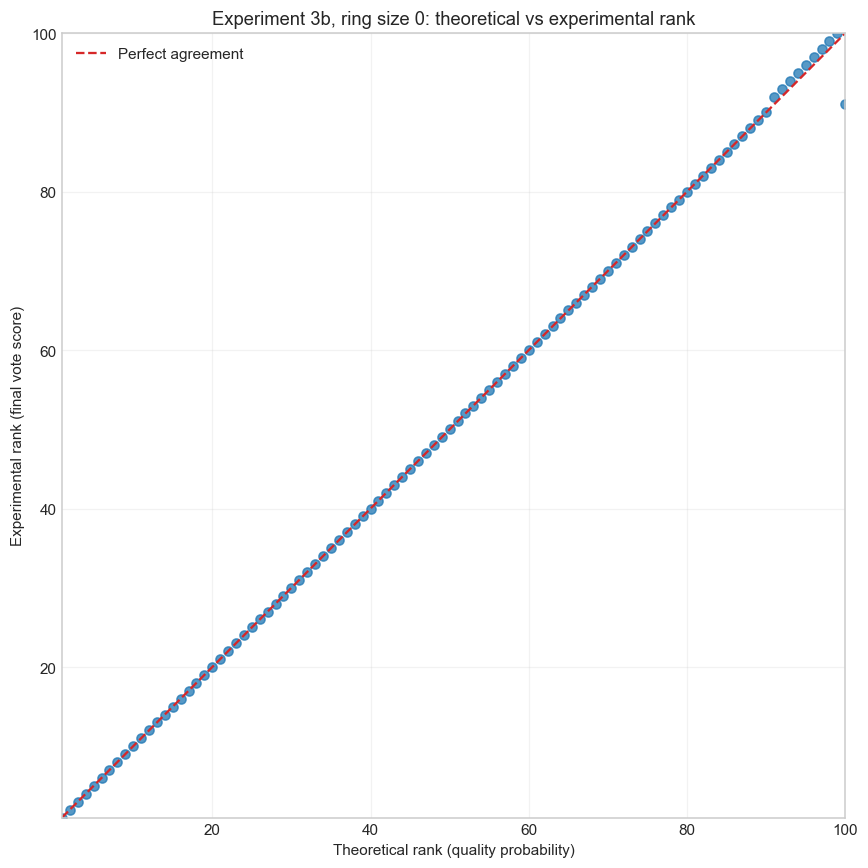

,experiment,post_id,theoretical_rank,experimental_rank,rank_difference,ideal_score,experimental_score,vote_count,absolute_rank_difference
98,"Experiment 3b, ring size 0",98,1,1,0,100.0,1.597238,80,0
1,"Experiment 3b, ring size 0",1,2,2,0,99.0,1.580233,80,0
6,"Experiment 3b, ring size 0",6,3,3,0,98.0,1.563136,80,0
26,"Experiment 3b, ring size 0",26,4,4,0,97.0,1.545939,80,0
4,"Experiment 3b, ring size 0",4,5,5,0,96.0,1.528634,80,0
...,...,...,...,...,...,...,...,...,...
78,"Experiment 3b, ring size 0",78,95,96,1,6.0,0.001261,80,1
81,"Experiment 3b, ring size 0",81,96,97,1,5.0,0.000967,80,1
80,"Experiment 3b, ring size 0",80,97,98,1,4.0,0.000717,80,1
15,"Experiment 3b, ring size 0",15,98,99,1,3.0,0.000505,80,1


Saved ring-size-0 comparison to D:\FYP\data\steem_demo\ring_zero_comparison.csv


In [9]:
ring_post_ranking_comparison = pd.concat([
    compare_rankings(result, f"Experiment 3, ring size {ring_size}").assign(
        ring_size=int(ring_size)
    )
    for ring_size, result in zip(ring_sizes, ring_ranking_results)
], ignore_index=True)

print("Detailed theoretical versus experimental rankings for every selfish-ring size:")
display(ring_post_ranking_comparison)

ring_comparison_summary = (
    ring_post_ranking_comparison
    .groupby("ring_size")
    .apply(summarize_ranking_comparison)
    .reset_index()
)
display(ring_comparison_summary)

ring_zero_result = CurationSimulation(
    players=100,
    posts=100,
    rounds=5_000,
    regen=ring_regen,
    attention_span=10,
    seed=20_000,
    selfish_players=20,
    quality_probabilities=quality_weights_a3b,
    selfish_quality_target=True,
    score_sigmoid_slope=score_sigmoid_slope_a3b,
    score_sigmoid_midpoint=score_sigmoid_midpoint_a3b,
 ).run(tracking_interval=500)

ring_zero_comparison = compare_rankings(ring_zero_result, "Experiment 3b, ring size 0")

fig, axis = plt.subplots(figsize=(8, 8))
axis.scatter(
    ring_zero_comparison["theoretical_rank"],
    ring_zero_comparison["experimental_rank"],
    alpha=0.75,
    color="tab:blue",
)
axis.plot([1, 100], [1, 100], linestyle="--", color="tab:red", label="Perfect agreement")
axis.set_xlabel("Theoretical rank (quality probability)")
axis.set_ylabel("Experimental rank (final vote score)")
axis.set_title("Experiment 3b, ring size 0: theoretical vs experimental rank")
axis.set_xlim(1, 100)
axis.set_ylim(1, 100)
axis.legend()
axis.grid(alpha=0.25)
plt.tight_layout()
plt.show()

display(ring_zero_comparison)
ring_zero_csv_path = Path("..") / "data" / "steem_demo" / "ring_zero_comparison.csv"
ring_zero_comparison.to_csv(ring_zero_csv_path, index=False)
print(f"Saved ring-size-0 comparison to {ring_zero_csv_path.resolve()}")

Experiment 4: whale voting for a low-quality post


,whale_voting_power,low_quality_post_id,initial_position,final_position,position_gained,final_kendall_tau,final_spearman_rho
0,1.0,90,100,100,0,1.000000,1.000000
1,2.0,90,100,99,1,0.999596,0.999988
2,5.0,90,100,97,3,0.998788,0.999928
3,10.0,90,100,95,5,0.997980,0.999820
4,25.0,90,100,91,9,0.996364,0.999460
5,50.0,90,100,88,12,0.995152,0.999064
6,100.0,90,100,83,17,0.993131,0.998164


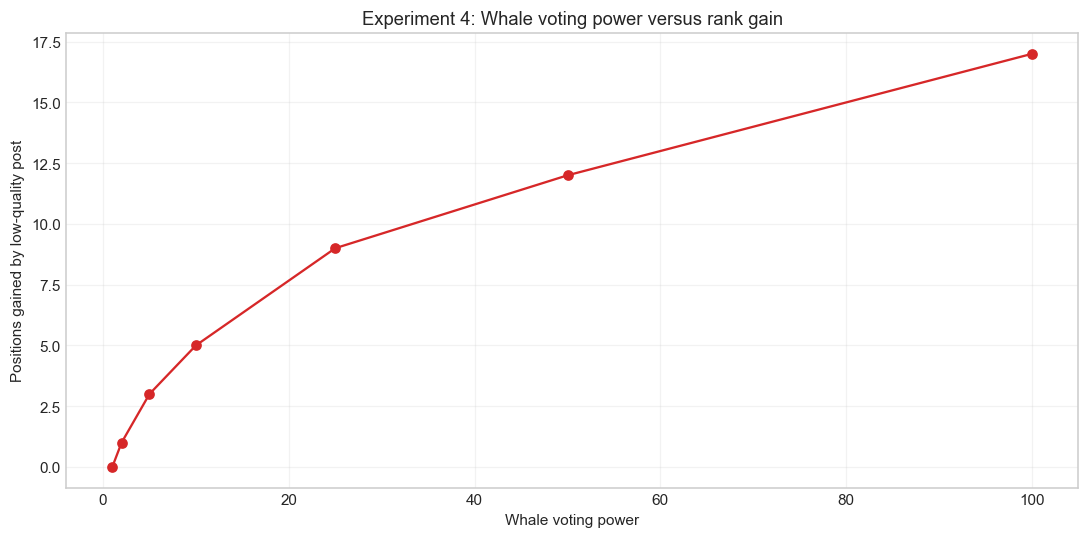

In [12]:
quality_probabilities_a4 = load_quality_probabilities(
    "simulation_post_features2.csv",
    100,
    "simulation_post_quality2.csv",
)
quality_weights_a4 = (
    pd.Series(quality_probabilities_a4)
    .rank(method="first", ascending=True)
    .to_numpy()
    / len(quality_probabilities_a4)
)

whale_powers_a4 = np.array([1, 2, 5, 10, 25, 50, 100], dtype=float)
experiment4_results = []

for whale_power in whale_powers_a4:
    simulation = CurationSimulation(
        players=101,
        posts=100,
        rounds=5_000,
        regen=ring_regen,
        attention_span=10,
        seed=40_000,
        selfish_players=1,
        quality_probabilities=quality_weights_a4,
        selfish_quality_target=True,
        whale_voting_power=whale_power,
        score_sigmoid_slope=10.0,
        score_sigmoid_midpoint=0.5
    )
    result = simulation.run(tracking_interval=500)

    final_position = int(
        np.flatnonzero(result.final_order == result.selfish_post_id)[0]
    ) + 1
    initial_position = 100

    experiment4_results.append({
        "whale_voting_power": whale_power,
        "low_quality_post_id": simulation.selfish_post_id,
        "initial_position": initial_position,
        "final_position": final_position,
        "position_gained": initial_position - final_position,
        "final_kendall_tau": result.kendall_tau[-1],
        "final_spearman_rho": result.spearman_rho[-1],
    })

experiment4_results = pd.DataFrame(experiment4_results)
print("Experiment 4: whale voting for a low-quality post")
display(experiment4_results)

fig, axis = plt.subplots(figsize=(10, 5))
axis.plot(
    experiment4_results["whale_voting_power"],
    experiment4_results["position_gained"],
    marker="o",
    color="tab:red",
)
axis.set_xlabel("Whale voting power")
axis.set_ylabel("Positions gained by low-quality post")
axis.set_title("Experiment 4: Whale voting power versus rank gain")
axis.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Content Curation and LLM Misinformation Attack Framework

This framework compares an unprotected Proof-of-Brain baseline with behavioral bot detection, sigmoid score attenuation, and reward gating.

In [6]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import kendalltau, spearmanr

In [10]:
from dataclasses import dataclass


@dataclass(frozen=True)
class MisinformationConfig:
    rounds: int = 28_800
    players: int = 300
    bot_players: int = 50
    posts: int = 100
    bot_posts: int = 20
    attention_span: int = 10
    a: float = 0.02
    b: float = 0.0001
    sp: float = 1.0
    regen: float = 3 / (5 * 24 * 60 * 60)
    sigmoid_slope: float = 10.0
    sigmoid_midpoint: float = 0.5

    def __post_init__(self) -> None:
        if self.rounds < 1 or self.players < 1 or self.posts < 1:
            raise ValueError("rounds, players, and posts must be positive")
        if not 0 <= self.bot_players <= self.players:
            raise ValueError("bot_players must be between 0 and players")
        if not 0 <= self.bot_posts <= self.posts:
            raise ValueError("bot_posts must be between 0 and posts")
        if self.attention_span < 1:
            raise ValueError("attention_span must be positive")


@dataclass
class MisinformationResult:
    rounds: np.ndarray
    kendall_tau: np.ndarray
    spearman_rho: np.ndarray
    ndcg_at_10: np.ndarray
    misinformation_rank: np.ndarray
    true_quality: np.ndarray
    apparent_quality: np.ndarray
    post_is_misinformation: np.ndarray
    author_bot_probability: np.ndarray
    final_scores: np.ndarray
    reward_scores: np.ndarray


def _normalized_sigmoid(value: float, slope: float, midpoint: float) -> float:
    sigmoid = lambda x: 1.0 / (1.0 + np.exp(-slope * x))
    lower = sigmoid(-midpoint)
    upper = sigmoid(1.0 - midpoint)
    return float((sigmoid(value - midpoint) - lower) / (upper - lower))


def _ndcg_at_10(order: np.ndarray, true_quality: np.ndarray) -> float:
    cutoff = min(10, len(order))
    gains = np.asarray(true_quality[order[:cutoff]], dtype=float)
    discounts = np.log2(np.arange(2, cutoff + 2))
    dcg = np.sum((2.0**gains - 1.0) / discounts)
    ideal_quality = np.sort(true_quality)[::-1][:cutoff]
    ideal_dcg = np.sum((2.0**ideal_quality - 1.0) / discounts)
    return float(dcg / ideal_dcg) if ideal_dcg else 0.0


class MisinformationCurationSimulation:
    """Simulate Proof-of-Brain voting with optional behavioral protection."""

    def __init__(self, config: MisinformationConfig, seed: int, protected: bool):
        self.config = config
        self.seed = seed
        self.protected = protected
        self.rng = np.random.default_rng(seed)

        bot_start = config.posts - config.bot_posts
        self.post_is_misinformation = np.arange(config.posts) >= bot_start
        self.true_quality = np.where(
            self.post_is_misinformation,
            self.rng.uniform(0.0, 0.1, config.posts),
            self.rng.uniform(0.1, 1.0, config.posts),
        )
        self.apparent_quality = np.where(
            self.post_is_misinformation,
            self.rng.uniform(0.90, 0.98, config.posts),
            self.true_quality,
        )
        self.author_bot_probability = np.where(
            self.post_is_misinformation,
            self.rng.beta(9.0, 1.0, config.posts),
            self.rng.beta(1.0, 9.0, config.posts),
        )
        self.initial_order = self.rng.permutation(config.posts)
        self.vote_rounds = np.array(sorted(make_vote_rounds(config.rounds, config.posts)))

    def _current_order(self, scores: np.ndarray) -> np.ndarray:
        return self.initial_order[np.argsort(-scores[self.initial_order], kind="stable")]

    def _metrics(self, order: np.ndarray) -> tuple[float, float, float, float]:
        true_order = np.argsort(-self.true_quality, kind="stable")
        true_position = np.empty(self.config.posts, dtype=int)
        true_position[true_order] = np.arange(self.config.posts)
        actual_position = np.empty(self.config.posts, dtype=int)
        actual_position[order] = np.arange(self.config.posts)
        tau = kendalltau(true_position, actual_position).statistic
        rho = spearmanr(true_position, actual_position).statistic
        bot_positions = actual_position[self.post_is_misinformation] + 1
        return (
            float(np.nan_to_num(tau, nan=1.0)),
            float(np.nan_to_num(rho, nan=1.0)),
            _ndcg_at_10(order, self.true_quality),
            float(np.mean(bot_positions)),
        )

    def run(self) -> MisinformationResult:
        config = self.config
        scores = np.zeros(config.posts, dtype=float)
        reward_scores = np.zeros(config.posts, dtype=float)
        voting_power = np.ones(config.players, dtype=float)
        voted = np.zeros((config.players, config.posts), dtype=bool)
        tracked_rounds = np.arange(config.rounds + 1)
        metric_rows = []

        def record(round_number: int, order: np.ndarray) -> None:
            metric_rows.append((round_number, *self._metrics(order)))

        record(0, self._current_order(scores))
        for round_number in range(1, config.rounds + 1):
            voting_power = np.minimum(voting_power + config.regen, 1.0)
            post_indices = np.flatnonzero(self.vote_rounds == round_number)
            if len(post_indices):
                order = self._current_order(scores)
                for player_id in range(config.players):
                    eligible = order[~voted[player_id, order]][:config.attention_span]
                    if len(eligible) == 0:
                        continue
                    if player_id >= config.players - config.bot_players:
                        bot_options = eligible[self.post_is_misinformation[eligible]]
                        candidates = bot_options if len(bot_options) else eligible
                    else:
                        candidates = eligible
                    selected_post = int(candidates[np.argmax(self.apparent_quality[candidates])])
                    vote_weight = float(self.apparent_quality[selected_post])
                    cost = config.a * voting_power[player_id] * vote_weight + config.b
                    raw_score = config.sp * cost
                    if self.protected:
                        effective_score = raw_score * (1.0 - self.author_bot_probability[selected_post])
                        contribution = _normalized_sigmoid(
                            effective_score,
                            config.sigmoid_slope,
                            config.sigmoid_midpoint,
                        )
                    else:
                        contribution = raw_score
                    scores[selected_post] += contribution
                    reward_scores[selected_post] += (
                        contribution * (1.0 - self.author_bot_probability[selected_post])
                        if self.protected else contribution
                    )
                    voting_power[player_id] = max(0.0, voting_power[player_id] - cost)
                    voted[player_id, selected_post] = True

            record(round_number, self._current_order(scores))

        metrics = np.asarray(metric_rows, dtype=float)
        return MisinformationResult(
            rounds=tracked_rounds,
            kendall_tau=metrics[:, 1],
            spearman_rho=metrics[:, 2],
            ndcg_at_10=metrics[:, 3],
            misinformation_rank=metrics[:, 4],
            true_quality=self.true_quality,
            apparent_quality=self.apparent_quality,
            post_is_misinformation=self.post_is_misinformation,
            author_bot_probability=self.author_bot_probability,
            final_scores=scores,
            reward_scores=reward_scores,
        )


def run_curation_comparison(config: MisinformationConfig, seed: int = 42):
    baseline = MisinformationCurationSimulation(config, seed=seed, protected=False).run()
    protected = MisinformationCurationSimulation(config, seed=seed, protected=True).run()
    return baseline, protected


def plot_curation_dashboard(
    baseline: MisinformationResult,
    protected: MisinformationResult,
) -> None:
    series = [
        ("Kendall's tau", baseline.kendall_tau, protected.kendall_tau),
        ("Spearman's rho", baseline.spearman_rho, protected.spearman_rho),
        ("nDCG@10 (true quality)", baseline.ndcg_at_10, protected.ndcg_at_10),
        ("Mean misinformation rank", baseline.misinformation_rank, protected.misinformation_rank),
    ]
    fig, axes = plt.subplots(2, 2, figsize=(15, 9), sharex=True)
    for axis, (title, baseline_values, protected_values) in zip(axes.flat, series):
        axis.plot(baseline.rounds, baseline_values, label="A: Unprotected", linewidth=1.8)
        axis.plot(protected.rounds, protected_values, label="B: Behaviorally gated", linewidth=1.8)
        axis.set_title(title)
        axis.set_xlabel("Round")
        axis.grid(alpha=0.25)
        axis.legend()
    axes[0, 0].set_ylabel("Correlation")
    axes[0, 1].set_ylabel("Correlation")
    axes[1, 0].set_ylabel("Score")
    axes[1, 1].set_ylabel("Rank")
    axes[1, 1].invert_yaxis()
    fig.suptitle("Proof-of-Brain curation under an LLM misinformation attack", fontsize=14)
    fig.tight_layout()
    plt.show()

In [14]:
def plot_curation_dashboard(
    baseline: MisinformationResult,
    protected: MisinformationResult,
) -> None:
    plots = [
        ("Kendall's tau", baseline.kendall_tau, protected.kendall_tau, "Correlation"),
        ("Spearman's rho", baseline.spearman_rho, protected.spearman_rho, "Correlation"),
        ("nDCG@10 (true quality)", baseline.ndcg_at_10, protected.ndcg_at_10, "Score"),
        ("Mean misinformation rank", baseline.misinformation_rank, protected.misinformation_rank, "Rank (lower is better)"),
    ]

    for title, baseline_values, protected_values, y_label in plots:
        fig, axis = plt.subplots(figsize=(12, 5))
        axis.plot(
            baseline.rounds,
            baseline_values,
            label="A: Unprotected",
            linewidth=1.8,
        )
        axis.plot(
            protected.rounds,
            protected_values,
            label="B: Behaviorally gated",
            linewidth=1.8,
        )
        axis.set_title(f"Proof-of-Brain: {title}")
        axis.set_xlabel("Round")
        axis.set_ylabel(y_label)
        axis.grid(alpha=0.25)
        axis.legend()
        if title == "Mean misinformation rank":
            axis.invert_yaxis()
        fig.tight_layout()
        plt.show()

,scenario,kendall_tau_final,spearman_rho_final,ndcg_at_10_final,mean_misinformation_rank_final,misinformation_reward_share
0,A: Unprotected Proof-of-Brain,0.268283,0.208713,0.387261,22.20,0.316096
1,B: Behaviorally-Gated Proof-of-Brain,0.724848,0.898542,0.927906,81.45,0.014433


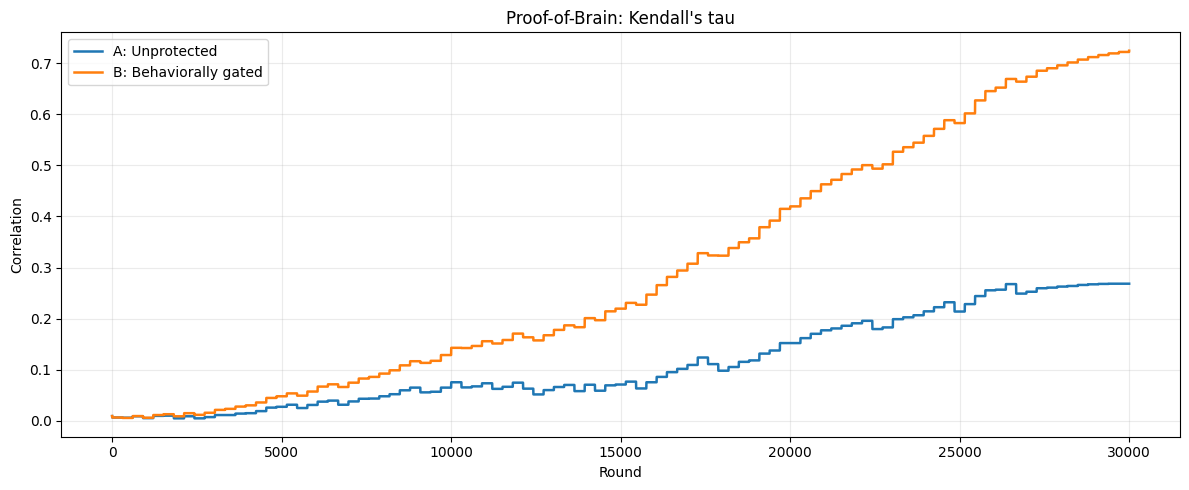

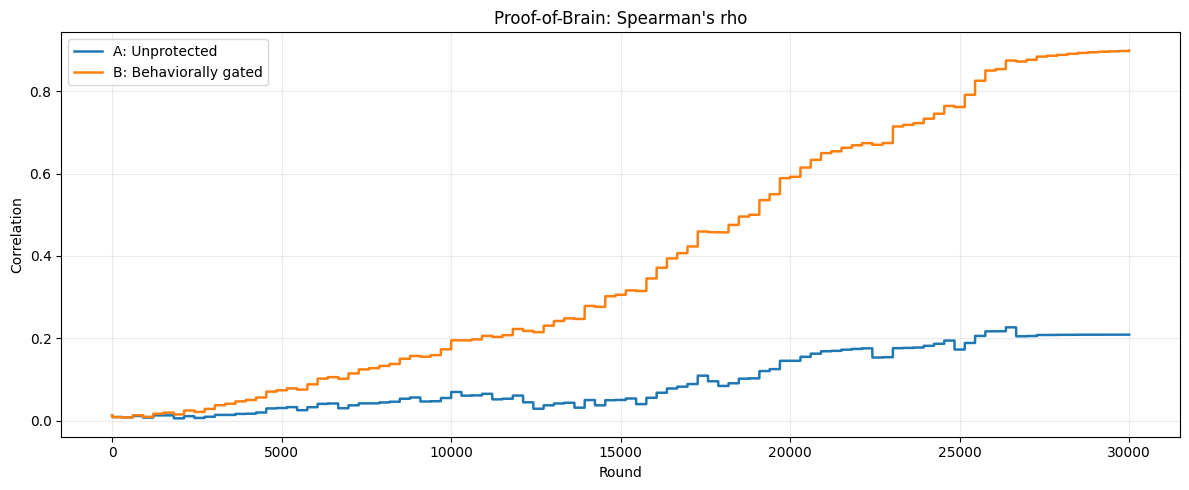

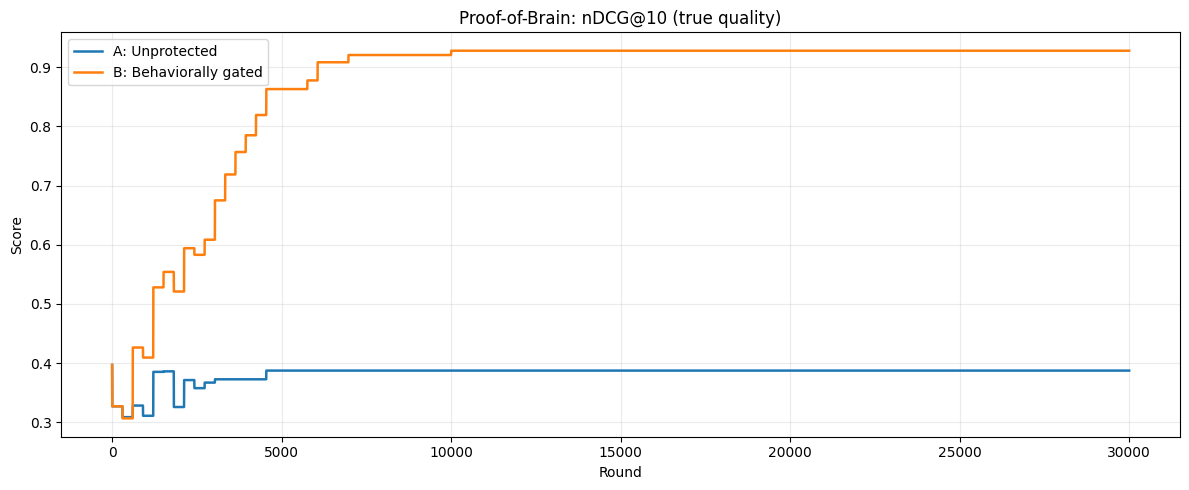

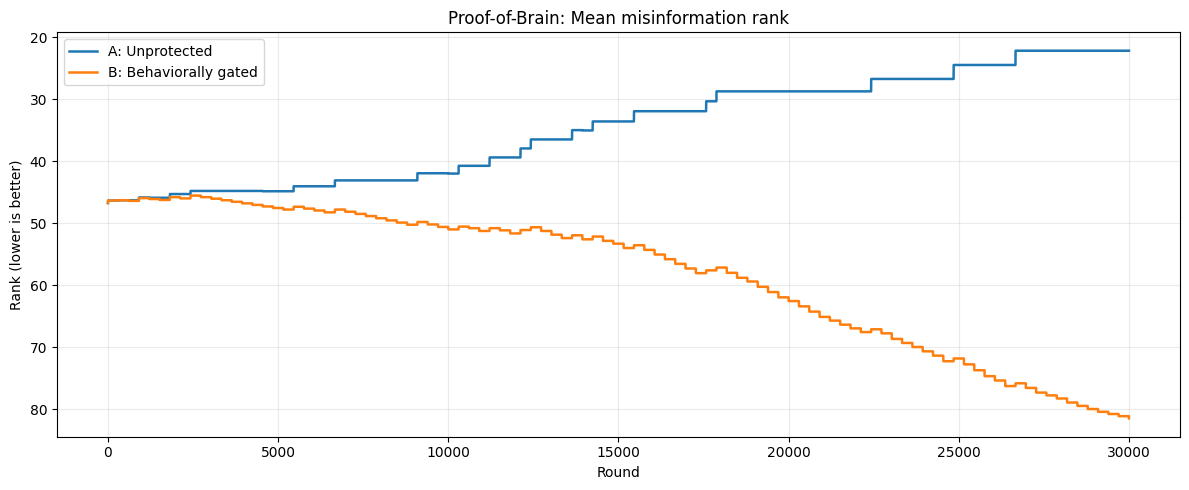

In [ ]:
# Run the required baseline and behaviorally gated scenarios with identical randomness.
EXPERIMENT_CONFIG = MisinformationConfig(
    rounds=5_000,
    players=300,
    bot_players=50,
    posts=100,
    bot_posts=20,
    attention_span=10,
)

baseline_result, protected_result = run_curation_comparison(
    EXPERIMENT_CONFIG,
    seed=42,
)

summary = pd.DataFrame([
    {
        "scenario": "A: Unprotected Proof-of-Brain",
        "kendall_tau_final": baseline_result.kendall_tau[-1],
        "spearman_rho_final": baseline_result.spearman_rho[-1],
        "ndcg_at_10_final": baseline_result.ndcg_at_10[-1],
        "mean_misinformation_rank_final": baseline_result.misinformation_rank[-1],
        "misinformation_reward_share": (
            baseline_result.reward_scores[baseline_result.post_is_misinformation].sum()
            / baseline_result.reward_scores.sum()
        ),
    },
    {
        "scenario": "B: Behaviorally-Gated Proof-of-Brain",
        "kendall_tau_final": protected_result.kendall_tau[-1],
        "spearman_rho_final": protected_result.spearman_rho[-1],
        "ndcg_at_10_final": protected_result.ndcg_at_10[-1],
        "mean_misinformation_rank_final": protected_result.misinformation_rank[-1],
        "misinformation_reward_share": (
            protected_result.reward_scores[protected_result.post_is_misinformation].sum()
            / protected_result.reward_scores.sum()
        ),
    },
])

display(summary)
plot_curation_dashboard(baseline_result, protected_result)

In [17]:
def _reward_share(scores: np.ndarray, post_indices) -> float:
    total_rewards = float(np.sum(scores))
    if total_rewards == 0.0:
        return 0.0
    return float(np.sum(scores[list(post_indices)]) / total_rewards)


reward_share_rows = []

for experiment_name, variable_name in [
    ("Experiment 1", "scenario_a1"),
    ("Experiment 2", "scenario_a2"),
    ("Experiment 1b", "scenario_a1b"),
    ("Experiment 2b", "scenario_a2b"),
]:
    result = globals().get(variable_name)
    if result is not None:
        reward_share_rows.append({
            "experiment": experiment_name,
            "statistic": "Top-10 true-quality reward share",
            "reward_share": _reward_share(result.scores, result.ideal_order[:10]),
        })

for scenario_name, variable_name in [
    ("A: Unprotected Proof-of-Brain", "baseline_result"),
    ("B: Behaviorally-Gated Proof-of-Brain", "protected_result"),
]:
    result = globals().get(variable_name)
    if result is not None:
        reward_share_rows.append({
            "experiment": scenario_name,
            "statistic": "Misinformation reward share",
            "reward_share": _reward_share(
                result.reward_scores,
                np.flatnonzero(result.post_is_misinformation),
            ),
        })

if "ring_ranking_results" in globals():
    reward_share_rows.append({
        "experiment": "Experiment 3",
        "statistic": "Mean selfish-post reward share across ring sizes",
        "reward_share": float(np.mean([
            _reward_share(result.scores, [result.selfish_post_id])
            for result in ring_ranking_results
        ])),
    })

if "ring_ranking_results_3b_by_slope" in globals():
    reward_share_rows.append({
        "experiment": "Experiment 3b (slope 6)",
        "statistic": "Mean low-quality-post reward share across ring sizes",
        "reward_share": float(np.mean([
            _reward_share(result.scores, [result.selfish_post_id])
            for result in ring_ranking_results_3b_by_slope[6.0]
        ])),
    })

if "ring_ranking_results_3c" in globals():
    reward_share_rows.append({
        "experiment": "Experiment 3c",
        "statistic": "Mean low-quality-post reward share across ring sizes",
        "reward_share": float(np.mean([
            _reward_share(result.scores, [result.selfish_post_id])
            for result in ring_ranking_results_3c
        ])),
    })

if "whale_powers_a4" in globals():
    experiment4_reward_rows = []
    for whale_power in whale_powers_a4:
        simulation = CurationSimulation(
            players=101,
            posts=100,
            rounds=5_000,
            regen=ring_regen,
            attention_span=10,
            seed=40_000,
            selfish_players=1,
            quality_probabilities=quality_weights_a4,
            selfish_quality_target=True,
            whale_voting_power=float(whale_power),
            score_sigmoid_slope=10.0,
            score_sigmoid_midpoint=0.5,
        )
        result = simulation.run(tracking_interval=500)
        experiment4_reward_rows.append({
            "experiment": f"Experiment 4 (whale power {whale_power:g})",
            "statistic": "Low-quality-post reward share",
            "reward_share": _reward_share(result.scores, [result.selfish_post_id]),
        })
    reward_share_rows.extend(experiment4_reward_rows)

reward_share_statistics = pd.DataFrame(reward_share_rows)
if not reward_share_statistics.empty:
    reward_share_statistics["reward_share_percent"] = (
        reward_share_statistics["reward_share"] * 100.0
    ).round(2)
display(reward_share_statistics)

,experiment,statistic,reward_share,reward_share_percent
0,A: Unprotected Proof-of-Brain,Misinformation reward share,0.316096,31.61
1,B: Behaviorally-Gated Proof-of-Brain,Misinformation reward share,0.014433,1.44
